![Banner](../images/03_06_banner_spatial_analysis_Segregation.png)






# Multiscale segregation profiles






## Overview

Every segregation index answers "how segregated?" at one scale: the scale of the tract or of the
chosen neighbourhood. Segregation is not scale-free. Two metro areas with the same tract-level
index can differ completely in **how far** their segregation extends: one may have a few
homogeneous blocks scattered through a mixed city, the other a single large divide between city
and suburbs.

A **multiscale segregation profile** (Reardon et al., 2008; Olteanu et al., 2019) follows each
tract's local environment outward. At radius $r$ it pools the population of every tract within $r$
and measures how far that pooled composition is from the metro composition. As $r$ grows the
environment eventually becomes the whole metro area and the divergence falls to zero; the speed of
that fall describes the scale of segregation.

This notebook follows the PySAL tutorials on
[multiscalar profiles and the KL divergence profile](https://pysal.org/segregation/tutorial.html)
using `seg.compute_profile` on Buffalo's census tracts (four named groups).

Topics:

- Divergence measures: Kullback-Leibler (KL) and L1
- Profile curves for individual tracts
- Mappable summaries: segregation scale, area under the curve, distortion
- Sensitivity to the threshold and divergence choice
- A metro-wide profile, and what it says about Theil's $H$
- Computational scaling with a KD-tree






## Setup

The next cell finds the repository root, puts it on the import path, points `DATA` at
`Data/03_spatial_analysis/data_segregation/buffalo`, imports `geolattice.spatial_analysis.segregation` as `seg`, and loads
the data.

**Study area and data.** The Buffalo-Cheektowaga metropolitan area: Erie and Niagara counties,
New York (about 1.17 million people in 2020). Counts come from the U.S. Census Bureau decennial
censuses of 2000, 2010, and 2020, by census tract, for five mutually exclusive groups:

| Column | Census definition |
|---|---|
| `white` | Not Hispanic or Latino, White alone |
| `black` | Not Hispanic or Latino, Black or African American alone |
| `hispanic` | Hispanic or Latino (any race) |
| `asian` | Not Hispanic or Latino, Asian alone |
| `other` | Everyone else (other single races and two or more races) |

Tract boundaries change between censuses. To compare years on the same units, the 2000 and 2010
counts have been moved onto the 323 tracts of 2020 with dasymetric interpolation weighted by 2020
housing units; notebook 03_07_07 shows how. Tracts with fewer than 100 residents (water, parks,
the airport) are dropped. `Data/03_spatial_analysis/data_segregation/make_buffalo_data.py` rebuilds everything from
the Census files in `Data/03_spatial_analysis/data_segregation/`.

Two map helpers keep every map in the same frame: `add_context(ax)` draws the county outlines,
and `metro_and_core(...)` shows the whole metro area next to a 30 km window centred on the City
of Buffalo, where most tracts are small.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for path setup and warning control.
import warnings  # silence noisy third-party warnings during demos
from pathlib import Path  # filesystem paths for locating sample data

# Third-party GIS / plotting / tabular stack used throughout the notebook.
import geopandas as gpd  # GeoDataFrame I/O for tracts and counties
import matplotlib.pyplot as plt  # figure and axes creation for maps
import numpy as np  # array ops for shares, norms, and masks
import pandas as pd  # tabular display of composition and indices
from IPython.display import display  # rich table previews in the notebook

# Hide library warnings so the notebook output stays readable.
warnings.filterwarnings("ignore")  # run this analysis or plotting step

# ===================================================================
# Setup for Buffalo metro segregation demos.
# Import GeoLattice, point DATA at Data/03_spatial_analysis/data_segregation/buffalo,
# import segregation as seg, load the tract panel, and define map helpers.
# ===================================================================

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

# Buffalo metro sample data (Erie + Niagara tracts on a shared 2020 geography).
DATA = ROOT / "Data" / "03_spatial_analysis" / "data_segregation" / "buffalo"  # define DATA

# Segregation indices, local measures, profiles, and inference helpers.
from geolattice.spatial_analysis import segregation as seg

# Compact figures with top/right spines removed for a cleaner look.
plt.rcParams.update(  # run this analysis or plotting step
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)
GROUPS = ["white", "black", "hispanic", "asian"]  # main race/ethnicity count columns
ALL_GROUPS = GROUPS + ["other"]  # include residual other category in totals
YEARS = (2000, 2010, 2020)  # panel years available in the sample

# Panel on the 2020 tract geometry (2000 and 2010 interpolated onto it).
tracts = {  # define tracts
    2000: gpd.read_file(DATA / "tracts_2000_on2020.geojson"),  # 2000 counts on 2020 boundaries
    2010: gpd.read_file(DATA / "tracts_2010_on2020.geojson"),  # 2010 counts on 2020 boundaries
    2020: gpd.read_file(DATA / "tracts_2020.geojson"),  # native 2020 tracts
}
counties = gpd.read_file(DATA / "counties.geojson")  # Erie and Niagara outlines
CORE = (662_000, 4_738_000, 692_000, 4_768_000)  # 30 km window on the City of Buffalo (UTM 17N, m)
CITY_HALL = (673_249, 4_750_383)  # City Hall marker for the core window


def add_context(ax, core=False, labels=True):
    """Draw county boundaries and optionally zoom to the City of Buffalo window."""
    counties.boundary.plot(ax=ax, color="0.25", lw=0.8)  # county outlines for context
    if core:  # apply the city-window zoom when requested
        ax.set_xlim(CORE[0], CORE[2])  # zoom to city window
        ax.set_ylim(CORE[1], CORE[3])  # run this analysis or plotting step
        ax.plot(*CITY_HALL, marker="*", color="k", ms=9, mec="white")  # City Hall star
    elif labels:
        for name, (x, y) in {  # iterate over the collection
            "Niagara Co.": (690_000, 4_790_000),  # run this analysis or plotting step
            "Erie Co.": (700_000, 4_715_000),  # run this analysis or plotting step
        }.items():  # run this analysis or plotting step
            ax.text(x, y, name, fontsize=8, color="0.25", ha="center")  # run this analysis or plotting step
    ax.set_axis_off()  # hide coordinate ticks on maps
    return ax  # return the computed result


def metro_and_core(
    gdf, values, title="", cmap="RdBu_r", norm=None, vmin=None, vmax=None,
    label="", significant=None, axes=None,  # define label
):
    """Side-by-side metro-wide and city-window choropleths of the same values."""
    if axes is None:  # create defaults when the caller omitted them
        fig, axes = plt.subplots(  # run this analysis or plotting step
            1, 2, figsize=(13, 6.2),  # run this analysis or plotting step
            gridspec_kw={"width_ratios": [1, 1.25]},  # define gridspec_kw
            constrained_layout=True,  # define constrained_layout
        )
    else:
        fig = axes[0].figure  # figure handle
    g = gdf.assign(_v=np.asarray(values, dtype=float))  # attach plot column
    kw = dict(  # extra keyword arguments for compute()
        column="_v", cmap=cmap, norm=norm,  # define column
        vmin=None if norm else vmin, vmax=None if norm else vmax,  # define vmin
        edgecolor="white", linewidth=0.2,  # define edgecolor
    )
    for ax, core in zip(axes, (False, True)):  # iterate paired sequences together
        g.plot(ax=ax, **kw)  # draw geometries or a series on the axes
        if significant is not None:  # hatch tracts that fail significance
            # Hatch tracts that are not statistically significant.
            g[~np.asarray(significant)].plot(  # draw geometries or a series on the axes
                ax=ax, facecolor="none", edgecolor="0.3", hatch="////", linewidth=0.2  # axes handle for drawing
            )
        add_context(ax, core=core)  # run this analysis or plotting step
    axes[0].set_title(f"{title}\nBuffalo metro (Erie + Niagara)", fontsize=10)  # set labels, title, or axis limits
    axes[1].set_title("City of Buffalo and inner suburbs (star = City Hall)", fontsize=10)  # set labels, title, or axis limits
    sm = plt.cm.ScalarMappable(  # mappable used to draw the colour bar
        cmap=cmap,  # define cmap
        norm=norm or plt.Normalize(  # matplotlib colour normalisation
            vmin if vmin is not None else np.nanmin(values),  # run this analysis or plotting step
            vmax if vmax is not None else np.nanmax(values),  # run this analysis or plotting step
        ),
    )
    fig.colorbar(sm, ax=list(axes), shrink=0.75, label=label)  # attach a colour bar to the figure
    return axes  # return the computed result


print("repo:", ROOT)  # run this analysis or plotting step
print("data:", DATA)  # run this analysis or plotting step
print("geopandas", gpd.__version__, "| CRS", tracts[2020].crs)  # run this analysis or plotting step
print({y: f"{len(g)} tracts, {g.total.sum():,.0f} people" for y, g in tracts.items()})  # run this analysis or plotting step


repo: /home/zia207/Github/GeoLattice
data: /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/data_segregation/buffalo
geopandas 1.1.4 | CRS EPSG:26917
{2000: '323 tracts, 1,170,053 people', 2010: '323 tracts, 1,135,475 people', 2020: '323 tracts, 1,166,882 people'}


## Part A: Profiles for individual tracts

For tract $i$ and radius $r$, let $\tilde{p}_{ik}(r)$ be group $k$'s share among everyone living
in tracts whose centroid is within $r$ of tract $i$ (including $i$ itself). Two divergences from
the metro composition $P_k$ are available:

$$\text{KL}_i(r) = \sum_k \tilde{p}_{ik}(r)\,\ln\frac{\tilde{p}_{ik}(r)}{P_k}, \qquad
\text{L1}_i(r) = \tfrac{1}{2}\sum_k |\tilde{p}_{ik}(r) - P_k|.$$

KL is the measure used in Reardon's profiles and in PySAL's `kl_divergence_profile`; it is the
same entropy logic as Theil's $H$. L1 is bounded in $[0, 1]$ and reads as "the share of the local
population that would need to change group for the environment to match the metro area".

`seg.compute_profile` evaluates every tract at every radius in one pass. Radius 0 means the tract
on its own. Buffalo's tracts range from a few hundred metres across in the city to more than 10 km
in rural Erie County, so the radii run to 30 km.






In [2]:
# ===================================================================
# Part A: Profiles for individual tracts.
# For tract $i$ and radius $r$, let $\tilde{p}_{ik}(r)$ be group $k$'s share among everyone living
# ===================================================================

RADII = [0, 1000, 2000, 3000, 5000, 8000, 12000, 16000, 20000, 30000]  # define RADII
prof = {y: seg.compute_profile(tracts[y], GROUPS, radii=RADII, divergence="kl", scale_threshold=0.05)  # spatial D across kernel bandwidths
        for y in YEARS}  # loop over panel years
p = prof[2020]  # tract share of the focal group within the pair
print("profile array:", p.profile.shape, "(tracts x radii)")  # status line for the notebook reader
pd.DataFrame(p.profile[:5], columns=[f"{r // 1000} km" for r in RADII],  # run this analysis or plotting step
             index=tracts[2020].tract_id[:5]).round(3)  # round for readable display



profile array: (323, 10) (tracts x radii)


,0 km,1 km,2 km,3 km,5 km,8 km,12 km,16 km,20 km,30 km
tract_id,,,,,,,,,,
36029009112,0.075,0.075,0.107,0.133,0.075,0.043,0.014,0.022,0.009,0.002
36029003800,1.174,1.099,0.897,0.651,0.391,0.121,0.038,0.015,0.007,0.001
36029006301,0.012,0.013,0.150,0.191,0.236,0.226,0.085,0.026,0.010,0.002
36029011400,0.053,0.038,0.051,0.050,0.020,0.032,0.053,0.020,0.008,0.001
36029010805,0.129,0.129,0.072,0.076,0.070,0.052,0.014,0.014,0.008,0.001


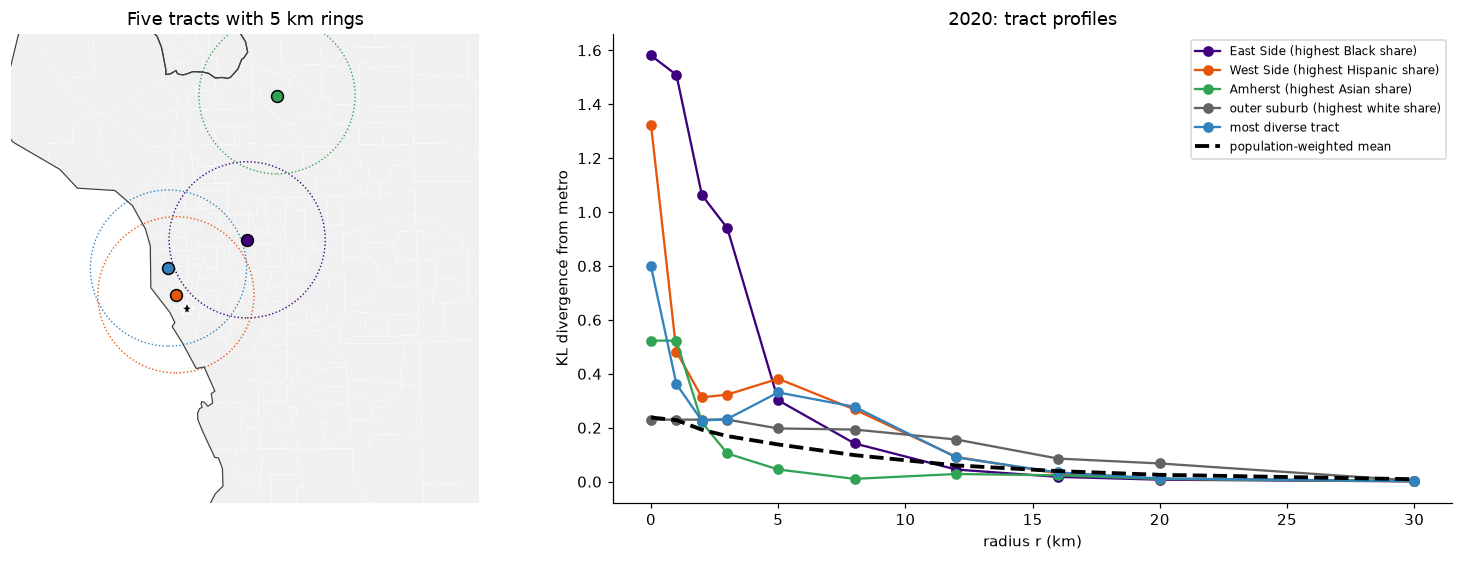

In [3]:
g = tracts[2020]  # working copy of one year's tracts
sh = g[GROUPS].div(g[GROUPS].sum(axis=1), axis=0)  # define sh
big = g.total > 2000  # define big
picks = {"East Side (highest Black share)": int(sh.black.where(big).idxmax()),  # define picks
         "West Side (highest Hispanic share)": int(sh.hispanic.where(big).idxmax()),  # run this analysis or plotting step
         "Amherst (highest Asian share)": int(sh.asian.where(big & (g.geometry.centroid.y > 4_758_000)).idxmax()),  # run this analysis or plotting step
         "outer suburb (highest white share)": int(sh.white.where(big).idxmax()),  # run this analysis or plotting step
         "most diverse tract": int(pd.Series(seg.local_entropy(g, GROUPS)).where(big).idxmax())}  # run this analysis or plotting step
colors = ["#3f007d", "#e6550d", "#31a354", "#636363", "#3182bd"]  # define colors

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.4]})  # create figure and axes
g.plot(ax=axes[0], color="#f0f0f0", edgecolor="white", lw=0.2)  # draw geometries or a series on the axes
for (name, i), col in zip(picks.items(), colors):  # iterate paired sequences together
    c = g.geometry.iloc[i].centroid  # define c
    axes[0].scatter(c.x, c.y, s=60, color=col, edgecolor="k", zorder=3)  # run this analysis or plotting step
    axes[0].add_patch(plt.Circle((c.x, c.y), 5000, fill=False, color=col, lw=0.9, ls=":"))  # run this analysis or plotting step
    axes[1].plot(np.array(RADII) / 1000, p.profile[i], marker="o", color=col, label=name)  # draw geometries or a series on the axes
add_context(axes[0], core=True); axes[0].set_title("Five tracts with 5 km rings")  # county outlines and optional city zoom
w = g[GROUPS].sum(axis=1).to_numpy()  # NumPy array view of the column
axes[1].plot(np.array(RADII) / 1000, (p.profile * w[:, None]).sum(0) / w.sum(), color="k", lw=2.5, ls="--",  # draw geometries or a series on the axes
             label="population-weighted mean")  # define label
axes[1].set(xlabel="radius r (km)", ylabel="KL divergence from metro", title="2020: tract profiles")  # set labels, title, or axis limits
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()  # render the figure in the notebook



Reading the curves:

- The **East Side** tract has by far the highest divergence at radius 0 and stays high out to
  3 km, because its neighbours are also mostly Black. It drops sharply only between 3 and 8 km,
  once the ring crosses into the surrounding white neighbourhoods. The East Side cluster is about
  that wide.
- The **West Side** tract also starts very high but falls by half within 1 to 2 km: the Hispanic
  concentration is a much smaller pocket. Its curve then rises again near 5 km as the ring reaches
  the East Side.
- The **Amherst** tract starts moderately high and converges within about 5 km.
- The **outer suburb** starts low (0.23) but stays above the metro mean out to 20 km: a low level of
  difference that extends a long way. The white suburban and rural ring is a very large homogeneous
  area.
- The **most diverse** tract also starts high. Diverse is not the same as typical: in a metro area
  that is 73% white, a tract with four equal groups is far from the metro mix.

The radius-0 value alone does not predict any of these shapes, which is the information a
single-scale index throws away.

## Part B: Mappable summaries

A curve per tract is hard to map. `MultiscaleProfile` stores three summaries, one value per tract:

| Summary | Definition | Reads as |
|---|---|---|
| `segregation_scale` | smallest radius where divergence falls below a threshold | how far you must go before the environment looks like the metro (`inf` = beyond the largest radius) |
| `auc` | area under the divergence-radius curve | segregation integrated over all scales |
| `distortion` | divergence at the largest radius / divergence at radius 0 | share of the tract's segregation that persists at the metro scale |






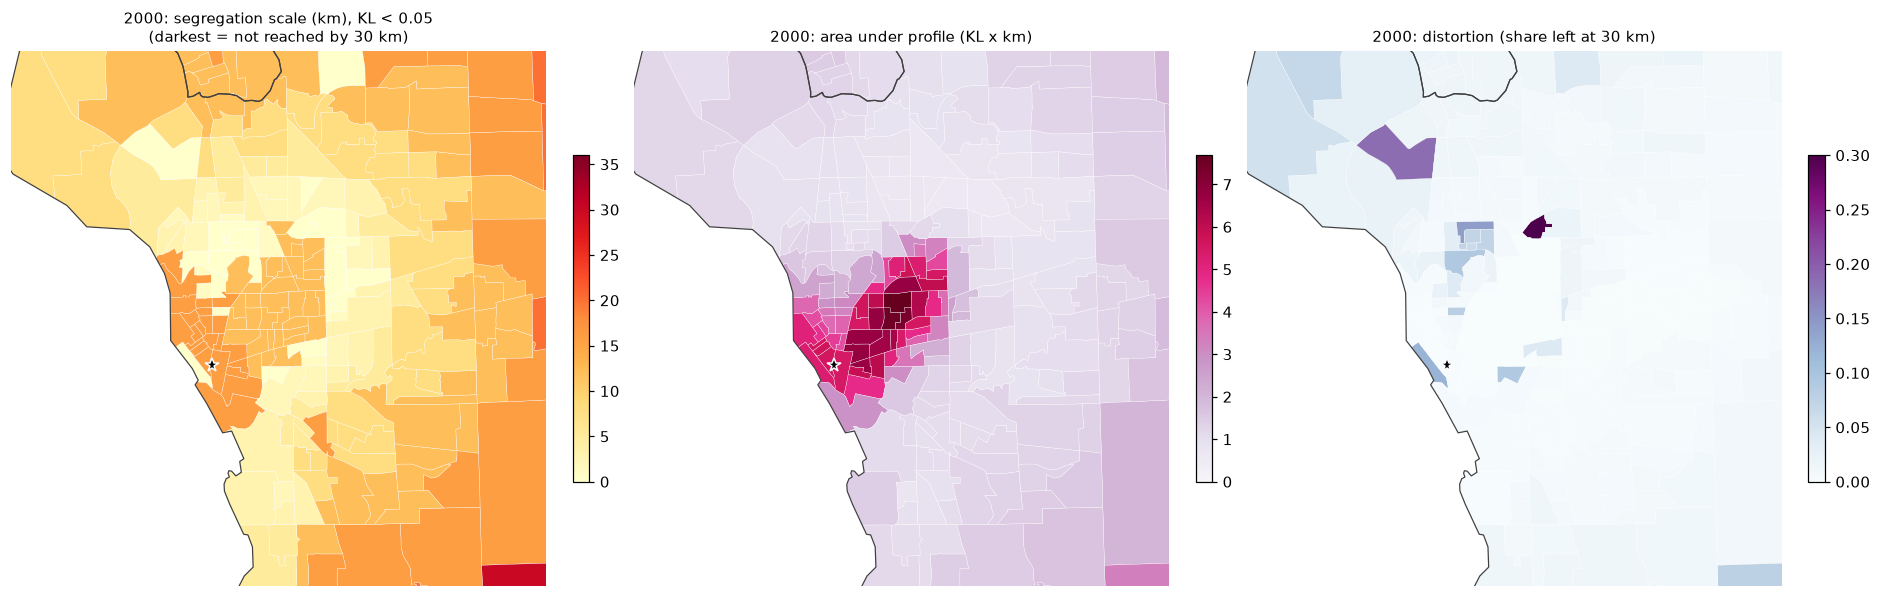

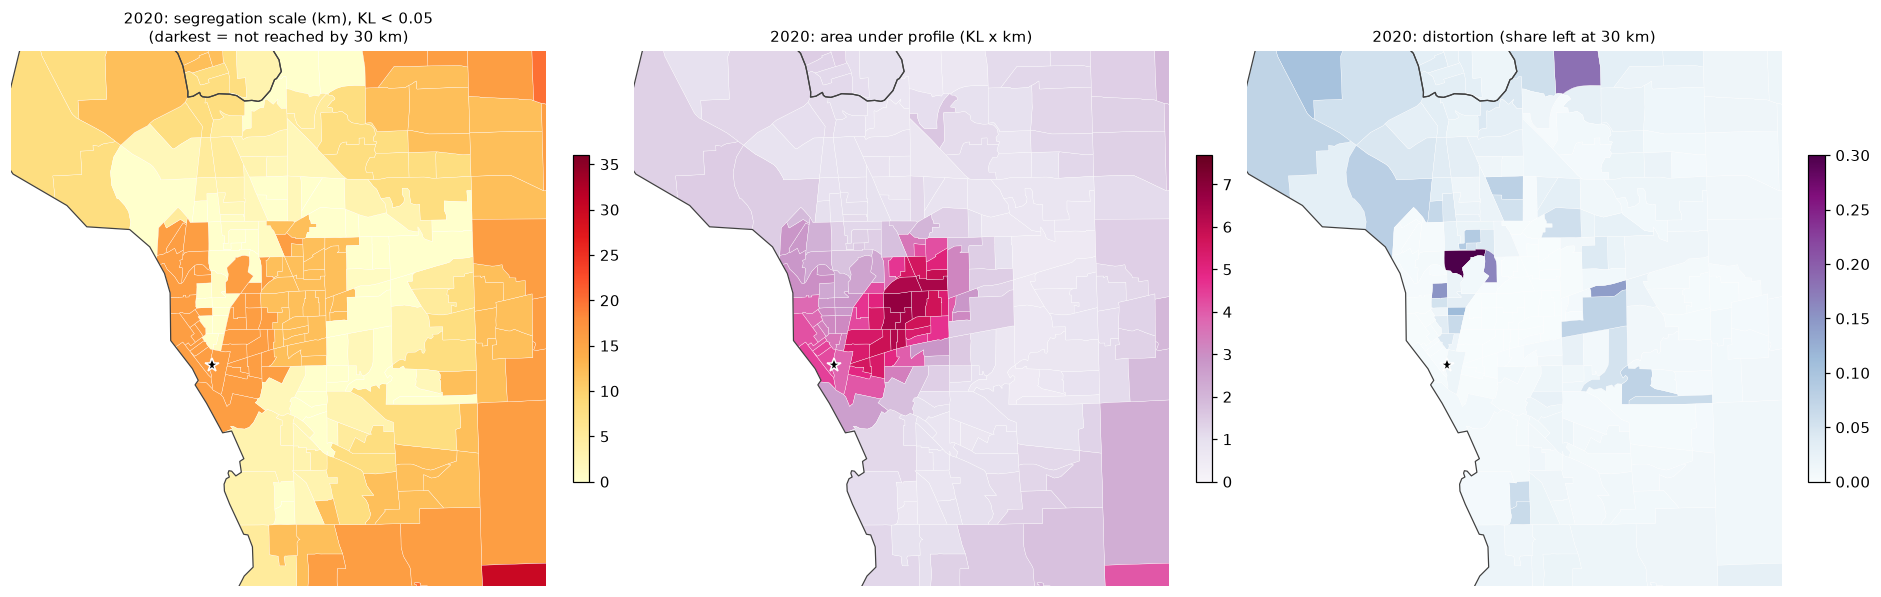

,2000,2010,2020
tracts not converged by 30 km,11.000,16.000,18.000
median scale of converged (km),12.000,12.000,12.000
mean AUC (KL x km),2.113,2.209,2.265
median distortion,0.011,0.017,0.020


In [4]:
# ===================================================================
# Part B: Mappable summaries.
# Reading the curves:
# ===================================================================

def capped_scale(pr, cap):
    return np.where(np.isfinite(pr.segregation_scale), pr.segregation_scale, cap) / 1000  # return the computed result

cap = RADII[-1] * 1.2  # define cap
for y in (2000, 2020):  # iterate over the collection
    pr = prof[y]  # define pr
    fig, axes = plt.subplots(1, 3, figsize=(17, 5.4), constrained_layout=True)  # create figure and axes
    for ax, vals, ttl, cmap, vmax in [  # iterate over the collection
        (axes[0], capped_scale(pr, cap), f"{y}: segregation scale (km), KL < 0.05\n(darkest = not reached by 30 km)", "YlOrRd", cap / 1000),  # run this analysis or plotting step
        (axes[1], pr.auc / 1000, f"{y}: area under profile (KL x km)", "PuRd", prof[2000].auc.max() / 1000),  # run this analysis or plotting step
        (axes[2], pr.distortion, f"{y}: distortion (share left at 30 km)", "BuPu", 0.3)]:  # run this analysis or plotting step
        tracts[y].assign(v=vals).plot(column="v", cmap=cmap, vmin=0, vmax=vmax, ax=ax, edgecolor="white", lw=0.2,  # draw geometries or a series on the axes
                                      legend=True, legend_kwds={"shrink": 0.6})  # define legend
        add_context(ax, core=True); ax.set_title(ttl, fontsize=10)  # county outlines and optional city zoom
    plt.show()  # render the figure in the notebook

pd.DataFrame({y: {"tracts not converged by 30 km": int(np.isinf(pr.segregation_scale).sum()),  # run this analysis or plotting step
                  "median scale of converged (km)": float(np.median(pr.segregation_scale[np.isfinite(pr.segregation_scale)])) / 1000,  # run this analysis or plotting step
                  "mean AUC (KL x km)": pr.auc.mean() / 1000, "median distortion": float(np.median(pr.distortion))}  # run this analysis or plotting step
              for y, pr in prof.items()}).round(3)  # round for readable display



Segregation is integrated over scale in the AUC map, and it concentrates on the East Side, with a
secondary area on the West Side. The scale map shows a ring structure: inner-suburban tracts
converge quickly (their surroundings mix city and suburb), while city tracts and the outer rural
tracts need 12 km or more, and some never converge within 30 km.

The summary table runs against the headline decline in $D$: the number of tracts that never
converge rises from 11 to 18, and the mean AUC and median distortion rise slightly. In KL terms the
*reach* of segregation did not shrink between 2000 and 2020.

## Part C: Threshold and divergence choices

The segregation scale depends on the threshold. There is no universal value; choose one that is
small relative to the radius-0 divergences, report it, and check that conclusions hold for
neighbouring values.






In [5]:
# ===================================================================
# Part C: Threshold and divergence choices.
# Segregation is integrated over scale in the AUC map, and it concentrates on the East Side, with a
# ===================================================================

rows = []  # accumulate one summary row per year / group
for y in YEARS:  # loop over panel years
    for div, thresholds in [("kl", [0.02, 0.05, 0.1]), ("l1", [0.05, 0.1, 0.15])]:  # iterate over the collection
        for th in thresholds:  # iterate over the collection
            pr = seg.compute_profile(tracts[y], GROUPS, radii=RADII, divergence=div, scale_threshold=th)  # define pr
            sc = pr.segregation_scale  # define sc
            rows.append({"year": y, "divergence": div, "threshold": th,  # append this year/group record
                         "share not converged": np.isinf(sc).mean(),  # run this analysis or plotting step
                         "median scale (km)": np.median(sc[np.isfinite(sc)]) / 1000})  # run this analysis or plotting step
sens = pd.DataFrame(rows)  # build table sens
display(sens.pivot_table(index=["divergence", "threshold"], columns="year", values="share not converged").round(2))  # show a rich table preview
sens.pivot_table(index=["divergence", "threshold"], columns="year", values="median scale (km)").round(1)  # run this analysis or plotting step



year                  2000  2010  2020
divergence threshold                  
kl         0.02       0.07  0.07  0.07
           0.05       0.03  0.05  0.06
           0.10       0.00  0.01  0.01
l1         0.05       0.09  0.07  0.09
           0.10       0.03  0.05  0.06
           0.15       0.00  0.01  0.02

year                  2000  2010  2020
divergence threshold                  
kl         0.02       16.0  16.0  16.0
           0.05       12.0  12.0  12.0
           0.10        5.0   5.0   5.0
l1         0.05       20.0  20.0  30.0
           0.10       12.0   8.0  12.0
           0.15        0.0   0.0   5.0

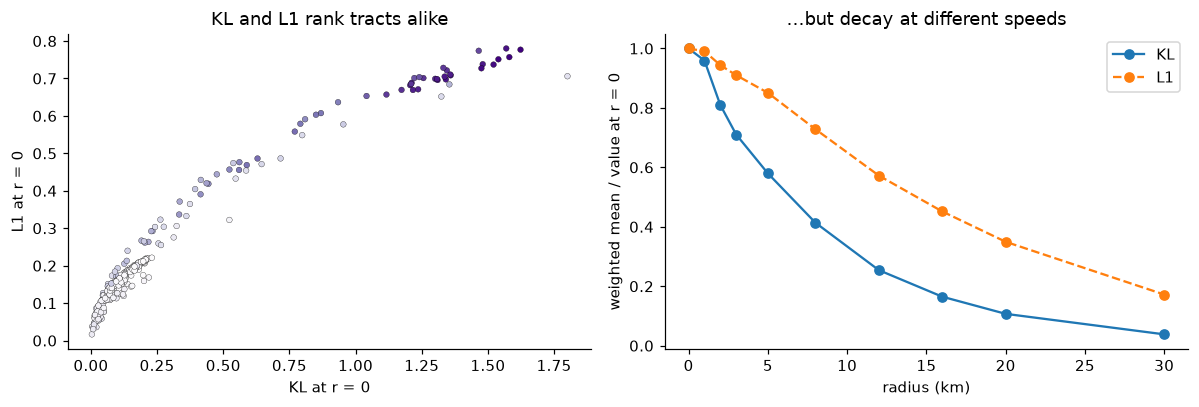

In [6]:
p_l1 = seg.compute_profile(tracts[2020], GROUPS, radii=RADII, divergence="l1")  # define p_l1
share_black = (g.black / g[GROUPS].sum(axis=1)).to_numpy()  # NumPy array view of the column
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))  # create figure and axes
axes[0].scatter(prof[2020].profile[:, 0], p_l1.profile[:, 0], s=14, c=share_black, cmap="Purples", edgecolor="k", lw=0.2)  # run this analysis or plotting step
axes[0].set(xlabel="KL at r = 0", ylabel="L1 at r = 0", title="KL and L1 rank tracts alike")  # set labels, title, or axis limits
for div, pr, ls in [("KL", prof[2020], "-"), ("L1", p_l1, "--")]:  # iterate over the collection
    m = (pr.profile * w[:, None]).sum(0) / w.sum()  # sum the selected values
    axes[1].plot(np.array(RADII) / 1000, m / m[0], ls=ls, marker="o", label=div)  # draw geometries or a series on the axes
axes[1].set(xlabel="radius (km)", ylabel="weighted mean / value at r = 0", title="...but decay at different speeds")  # set labels, title, or axis limits
axes[1].legend(); plt.tight_layout(); plt.show()  # render the figure in the notebook



KL and L1 order tracts similarly at any one radius, but KL falls faster with radius because it
weights departures roughly quadratically when they are small. Thresholds are therefore not
interchangeable between the two measures. KL is the conventional choice; L1 is easier to explain.

## Part D: A metro-wide profile, and a lesson about Theil's $H$

Averaging tract profiles with population weights gives one curve per year. At radius 0 this
weighted mean has a precise meaning: it is the **mutual information** between tract and group,
which equals $H \times E$ (Theil's $H$ times the metro entropy). So the profile also shows
*why* $H$ changed.






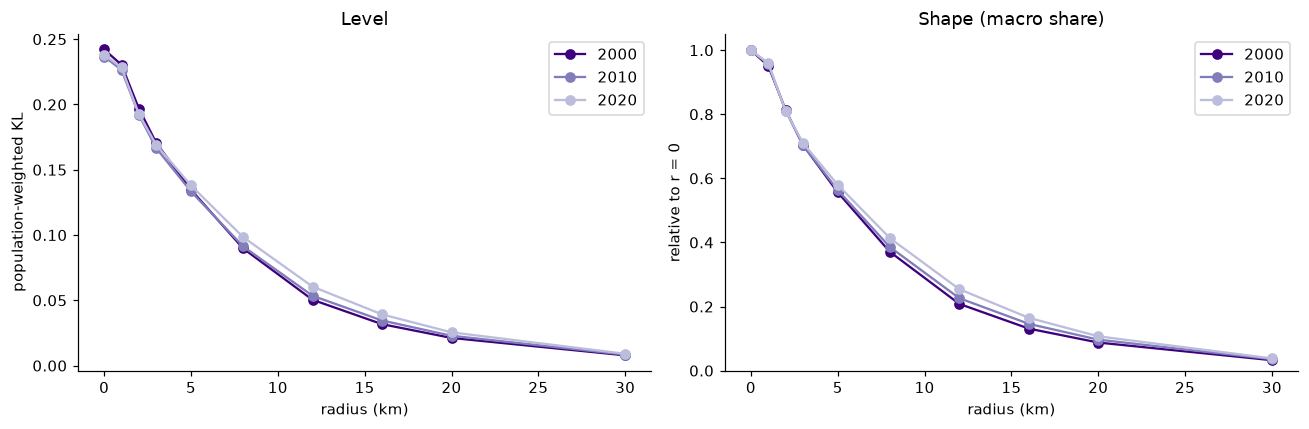

,weighted KL at r = 0,metro entropy E,KL / E,Theil H,share left at 5 km,share left at 12 km,share left at 20 km
2000,0.242,0.558,0.434,0.434,0.556,0.208,0.088
2010,0.237,0.643,0.368,0.368,0.563,0.226,0.097
2020,0.238,0.778,0.306,0.306,0.580,0.254,0.107


In [7]:
# ===================================================================
# Part D: A metro-wide profile, and a lesson about Theil's $H$.
# KL and L1 order tracts similarly at any one radius, but KL falls faster with radius because it
# ===================================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # create figure and axes
rows = {}  # accumulate summary rows
for y, col in zip(YEARS, ["#3f007d", "#807dba", "#bcbddc"]):  # loop over panel years  # iterate paired sequences together
    wy = tracts[y][GROUPS].sum(axis=1).to_numpy()  # NumPy array view of the column
    metro = (prof[y].profile * wy[:, None]).sum(0) / wy.sum()  # sum the selected values
    axes[0].plot(np.array(RADII) / 1000, metro, marker="o", color=col, label=str(y))  # draw geometries or a series on the axes
    axes[1].plot(np.array(RADII) / 1000, metro / metro[0], marker="o", color=col, label=str(y))  # draw geometries or a series on the axes
    P = tracts[y][GROUPS].sum() / tracts[y][GROUPS].sum().sum()  # sum the selected values
    E = float(-(P * np.log(P)).sum())  # sum the selected values
    rows[y] = {"weighted KL at r = 0": metro[0], "metro entropy E": E, "KL / E": metro[0] / E,  # assign a derived column or cell
               "Theil H": seg.theil_h(tracts[y], GROUPS),  # run this analysis or plotting step
               **{f"share left at {r // 1000} km": metro[RADII.index(r)] / metro[0] for r in (5000, 12000, 20000)}}  # run this analysis or plotting step
axes[0].set(xlabel="radius (km)", ylabel="population-weighted KL", title="Level")  # set labels, title, or axis limits
axes[1].set(xlabel="radius (km)", ylabel="relative to r = 0", title="Shape (macro share)", ylim=(0, 1.05))  # set labels, title, or axis limits
for a in axes: a.legend()  # iterate over the collection
plt.tight_layout(); plt.show()  # render the figure in the notebook
pd.DataFrame(rows).T.round(3)  # round for readable display



This is the most important table in the notebook.

- The weighted KL at radius 0, the mutual information between tract and group, is essentially
  **unchanged**: 0.242 in 2000 and 0.238 in 2020. How much a resident's tract tells you about
  their group has not fallen.
- Metro entropy $E$ rose from 0.56 to 0.78 as the Hispanic and Asian populations grew. Because
  $H = \text{KL}/E$, Theil's $H$ fell from 0.43 to 0.31 **entirely through its denominator**.
- The shape also shifted toward larger scales: 25% of the radius-0 divergence remains at 12 km
  in 2020, against 21% in 2000.

Put together with notebook 03_07_01: Black-white sorting declined, but the growing Hispanic and
Asian populations are themselves sorted (Part A of notebook 03_07_03), so total multigroup
sorting held steady while the metro area diversified. Which statement is "right" depends on the
question: the normalized $H$ answers "how segregated relative to how diverse"; the mutual
information answers "how much does place predict group". Report both when diversity is changing.

## Part E: Comparing with PySAL's KL profile

PySAL's `compute_divergence_profiles` returns, for each origin tract, the KL divergence after
adding tracts one at a time in order of distance. It should agree with `compute_profile` at the
same radii. If PySAL is installed, the cell below checks a few tracts.






In [8]:
# ===================================================================
# Part E: Comparing with PySAL's KL profile.
# This is the most important table in the notebook.
# ===================================================================

try:
    from segregation.dynamics import compute_divergence_profiles  # library import used below
except ImportError:  # tell the reader how to install the optional dependency
    print("PySAL `segregation` not installed: pip install segregation to run this check")  # status line for the notebook reader
else:
    pys = compute_divergence_profiles(tracts[2020], groups=GROUPS)  # define pys
    id_col = "observation" if "observation" in pys.columns else "c_id"  # column name differs by PySAL version
    rows = []  # accumulate one summary row per year / group
    for unit in [0, 100, 200]:  # iterate over the collection
        d = pys[pys[id_col] == unit].sort_values("distance")  # define d
        for r in (0, 5000, 12000):  # iterate over the collection
            rows.append({"tract": tracts[2020].tract_id[unit], "radius (m)": r,  # append this year/group record
                         "PySAL": d[d.distance <= r].divergence.iloc[-1],
                         "GeoLattice": prof[2020].profile[unit, RADII.index(r)]})  # run this analysis or plotting step
    cmp_ = pd.DataFrame(rows); cmp_["abs diff"] = (cmp_.PySAL - cmp_.GeoLattice).abs()  # build table cmp_
    display(cmp_.round(6))  # show a rich table preview


PySAL `segregation` not installed: pip install segregation to run this check


## Part F: Scaling to many units

Buffalo's 323 tracts are small. Block groups or census blocks (about 15,000 populated blocks here)
quickly make the problem large. A profile needs, for every unit, the cumulative population within
each radius. The direct approach builds an $n \times n$ distance matrix, which needs $8n^2$ bytes:
800 MB at $n = 10{,}000$ and 1.8 GB for Buffalo's 15,000 populated blocks. `compute_profile` queries a
`cKDTree` for each unit's nearest neighbours in chunks, so memory grows with $n \times$ (neighbours
per unit). (Recent PySAL releases also fall back to streaming KD-tree queries when the dense matrix
would not fit; older ones did not.)

The benchmark uses the **real 2020 census blocks** of Erie and Niagara counties (block internal
points with population; group counts are not published at block level in this file, so
synthetic group labels are drawn from the metro shares, which affects only the values, not the
cost). It compares `compute_profile` with a dense NumPy implementation on random subsets.






In [9]:
# ===================================================================
# Part F: Scaling to many units.
# Buffalo's 323 tracts are small. Block groups or census blocks (about 15,000 populated blocks here)
# ===================================================================

import time  # library import used below
from scipy.spatial.distance import cdist  # library import used below

blocks = gpd.read_file(DATA / "blocks_2020_points.geojson")  # load vector features from disk
blocks = blocks[blocks.pop20 > 0].reset_index(drop=True)  # index rows for keyed lookup / display
print(f"{len(blocks):,} populated 2020 blocks, {blocks.pop20.sum():,.0f} people")  # status line for the notebook reader

def dense_profile(xy, counts, radii):
    D = cdist(xy, xy)  # define D
    P = counts.sum(0) / counts.sum()  # sum the selected values
    out = np.empty((len(xy), len(radii)))  # define out
    for j, r in enumerate(radii):  # iterate with a numeric index
        pooled = (D <= r).astype(float) @ counts  # tract table with kernel-pooled group counts
        q = pooled / pooled.sum(1, keepdims=True)  # define q
        out[:, j] = np.sum(np.where(q > 0, q * np.log(q / P), 0), axis=1)  # temporary plot column for the choropleth
    return out  # return the computed result

rng = np.random.default_rng(0)  # reproducible random generator
P20 = (tracts[2020][GROUPS].sum() / tracts[2020][GROUPS].sum().sum()).to_numpy()  # sum the selected values
bench, radii_b = [], [250, 500, 1000]
for n in [1000, 2500, 5000, 10000, len(blocks)]:  # iterate over the collection
    sub = blocks.sample(n, random_state=1) if n < len(blocks) else blocks  # define sub
    counts = np.array([rng.multinomial(int(t), P20) for t in sub.pop20]).astype(float)  # define counts
    pts = gpd.GeoDataFrame(pd.DataFrame(counts, columns=GROUPS), geometry=sub.geometry.values, crs=sub.crs)  # build table pts
    t0 = time.perf_counter(); kd = seg.compute_profile(pts, GROUPS, radii=radii_b, chunk_size=1000); t_kd = time.perf_counter() - t0  # define t0
    row = {"units": n, "KD-tree time (s)": t_kd, "dense matrix memory (GB)": 8 * n**2 / 1e9}  # define row
    if n <= 5000:  # conditional branch
        xy = np.c_[pts.geometry.x, pts.geometry.y]  # define xy
        t0 = time.perf_counter(); dn = dense_profile(xy, counts, radii_b); row["dense time (s)"] = time.perf_counter() - t0  # define t0
        row["max abs diff"] = float(np.abs(dn - kd.profile).max())  # absolute gap between group share schedules
    bench.append(row)  # append this year/group record
bench = pd.DataFrame(bench).set_index("units")  # build table bench
bench.round(4)  # run this analysis or plotting step


15,076 populated 2020 blocks, 1,166,902 people


,KD-tree time (s),dense matrix memory (GB),dense time (s),max abs diff
units,,,,
1000,0.0368,0.0080,0.0061,0.0
2500,0.1961,0.0500,0.0457,0.0
5000,0.4039,0.2000,0.1855,0.0
10000,0.7355,0.8000,NaN,NaN
15076,1.0192,1.8183,NaN,NaN


Both approaches give the same numbers (maximum difference zero). For a few thousand units the
dense method is faster, because a matrix product is very efficient. Its memory, however, grows
with $n^2$: 1.8 GB for all 15,076 populated blocks in Erie and Niagara counties, and 200 GB or more
for a large metro area. The KD-tree approach handles all Buffalo blocks in about 3 seconds with
memory that grows roughly linearly.

Two practical notes:

- `max_neighbors` (default 2000) caps how many neighbours each unit can pool. If a unit has more
  units within the largest radius, `compute_profile` raises an error rather than silently
  truncating. Raise it, or shrink the largest radius.
- Radii are Euclidean distances between centroids in the layer's CRS, so use a projected CRS in
  metres (here NAD83 / UTM zone 17N).

## Summary

- A multiscale profile tracks how a tract's surrounding population converges to the metro
  composition as the radius grows. **Level** and **reach** of segregation are separate properties.
- `segregation_scale`, `auc`, and `distortion` turn the profiles into maps; the scale depends on a
  threshold that should be reported and varied.
- KL and L1 rank tracts alike but decay at different rates, so thresholds are measure-specific.
- The population-weighted profile at radius 0 is the mutual information $H \times E$. Comparing it
  with $H$ separates a change in *sorting* from a change in *diversity*.
- `compute_profile` matches PySAL's KL profile and handles block-level data without an
  $n \times n$ matrix.

**Next:** 03_07_05 builds the null models that tell us which of these patterns could arise by chance.

## References

- Olteanu, M., Randon-Furling, J., & Clark, W. A. V. (2019). Segregation through the multiscalar lens. *PNAS*, 116(25), 12250-12254.
- Reardon, S. F., Matthews, S. A., O'Sullivan, D., Lee, B. A., Firebaugh, G., Farrell, C. R., & Bischoff, K. (2008). The geographic scale of metropolitan racial segregation. *Demography*, 45(3), 489-514.
- Reardon, S. F., & Firebaugh, G. (2002). Measures of multigroup segregation. *Sociological Methodology*, 32(1), 33-67.
- Wong, D. W. S. (2004). Comparing traditional and spatial segregation measures: a spatial scale perspective. *Urban Geography*, 25(1), 66-82.




